# 02a — Speed–endurance profile

Part of [Proposal 2](../proposals/02-bottleneck-identifier.md). Before scoring
limiters: how does this athlete's performance fall off with distance, and where
does their speed ceiling sit?

- **Race VDOT by distance**: equal VDOT across distances means a balanced runner.
- **Personal Riegel exponent** *b* in time ∝ distance^b (typical ≈ 1.06): higher =
  fades more with distance (endurance-limited), lower = relatively short of speed.
- **Critical speed (CS) and D′** from best efforts lasting 2–20 minutes.

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from goalsplit_research import data, datasets, limiters as L

pd.set_option("display.width", 140)
plt.rcParams.update({"figure.figsize": (11, 3.4), "axes.spines.top": False, "axes.spines.right": False})

ds = data.fetch_dataset()
acts = data.activities_frame(ds)
races = datasets.road_races(ds, acts)
best_efforts = data.best_efforts()
print(f"{len(races)} road races · data to {ds['today']}")

15 road races · data to 2026-10-26


## Race VDOT against distance

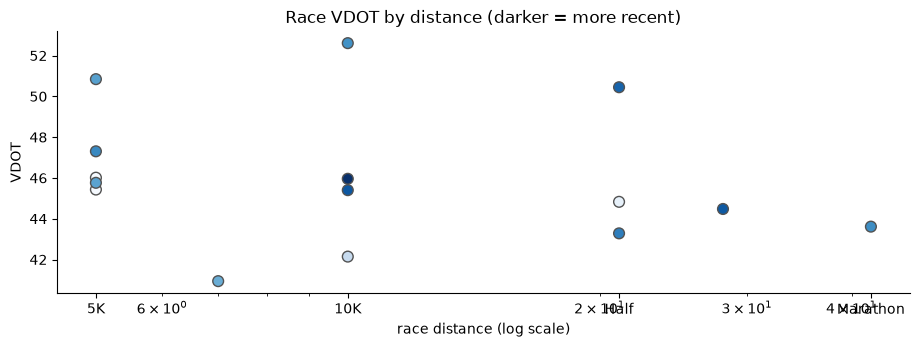

            count  median   max
km                             
≤7.5 km         6    45.9  50.8
10 km           4    45.7  52.6
half–30 km      4    44.7  50.4
marathon        1    43.6  43.6


In [2]:
races["km"] = races["distance_m"] / 1000
fig, ax = plt.subplots()
sc = ax.scatter(races["km"], races["vdot"], c=(races["localDate"] - races["localDate"].min()).dt.days, cmap="Blues", s=60, edgecolor="#525252")
ax.set_xscale("log")
ax.set_xticks([5, 10, 21.1, 42.2]); ax.set_xticklabels(["5K", "10K", "Half", "Marathon"])
ax.set_xlabel("race distance (log scale)"); ax.set_ylabel("VDOT")
ax.set_title("Race VDOT by distance (darker = more recent)")
plt.show()

by_band = races.groupby(pd.cut(races["km"], [0, 7.6, 15, 30, 50], labels=["≤7.5 km", "10 km", "half–30 km", "marathon"]), observed=True)["vdot"]
print(by_band.agg(["count", "median", "max"]).round(1).to_string())

## Personal Riegel exponent

`log(time) = a + b·log(distance) + c·years`. The years term absorbs fitness changing
over 2.5 years, so a recent fast 5K and an old slow marathon don't get read as
distance fatigue. 95% bootstrap interval over races.

In [3]:
riegel = L.riegel_exponent(races, n_boot=4000)
print(f"b = {riegel['b']:.3f}  (95% CI {riegel['ci_low']:.3f}–{riegel['ci_high']:.3f}, n = {riegel['n']} races, "
      f"{riegel['distance_span_km'][0]:.0f}–{riegel['distance_span_km'][1]:.0f} km)")
print("Reference: ~1.06 typical; higher = fades more with distance.")

# What the exponent means in minutes: marathon predicted from the half
half = 1 * 3600 + 30 * 60 + 49  # Firenze Half
for label, b in [("typical (1.06)", 1.06), ("yours", riegel["b"])]:
    t = half * (42195 / 21097.5) ** b
    print(f"Marathon from a {half // 3600}:{half % 3600 // 60:02d}:{half % 60:02d} half, {label}: {int(t // 3600)}:{int(t % 3600 // 60):02d}:{int(t % 60):02d}")

b = 1.084  (95% CI 1.044–1.119, n = 15 races, 5–42 km)
Reference: ~1.06 typical; higher = fades more with distance.
Marathon from a 1:30:49 half, typical (1.06): 3:09:20
Marathon from a 1:30:49 half, yours: 3:12:29


## Critical speed and D′

In [4]:
cs = L.critical_speed(best_efforts, ds["today"])
if cs:
    pace = 1000 / cs["cs_m_s"]
    print(f"CS = {cs['cs_m_s']:.2f} m/s ({int(pace // 60)}:{int(pace % 60):02d}/km), D′ = {cs['d_prime_m']:.0f} m, R² = {cs['r2']:.4f}")
    print("From:", ", ".join(f"{e['effort']} in {e['elapsed_s'] // 60}:{e['elapsed_s'] % 60:02d}" for e in cs["efforts"]))
    print("D′ is the distance you can cover above CS before tiring; typical trained runners show roughly 150–300 m.")
else:
    print("Not enough best efforts lasting 2–20 minutes in the last year.")

CS = 4.07 m/s (4:05/km), D′ = 82 m, R² = 0.9999
From: 1 mile in 6:19, 1/2 mile in 2:56, 1K in 3:44, 2 mile in 12:49
D′ is the distance you can cover above CS before tiring; typical trained runners show roughly 150–300 m.


## Conclusions

**Balanced up to the half, with a mild fade beyond.** Median race VDOT is about 45–46
for ≤7.5 km, 10 km and half-marathon races alike. The personal Riegel exponent is
**1.084 (95% CI 1.044–1.119)**: slightly more fade with distance than the typical 1.06,
though the interval includes it.

**The one road marathon fell well short of even that.** With the personal exponent,
the Firenze Half (1:30:49) predicts a 3:12 marathon; Venice was 3:33:46. One race
can't establish a pattern, and Venice came five months *before* the faster half, so
part of the gap is fitness changing. Still, it's consistent with a marathon-specific
durability gap that shorter races don't reveal.

**Speed ceiling: untested rather than weak.** Critical speed is 4.07 m/s (4:05/km),
but D′ is only 82 m, well under the roughly 150–300 m typical of trained runners.
The 2–20 minute "best efforts" are segments of training runs, not all-out efforts,
so the athlete's anaerobic reserve has never been measured. Speed findings get low
confidence until there are genuinely maximal short efforts (e.g. a 1-mile or 3 km
time trial).